In [3]:
import cv2
import torch
import numpy as np
from PIL import Image

# ------------------------------------------------------------
# 1. Load video
# ------------------------------------------------------------

video_path = "../data/human_demo.mp4"

cap = cv2.VideoCapture(video_path)
frames = []

while True:
    ok, frame = cap.read()
    if not ok:
        break

    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append(frame)

cap.release()

# CoTracker expects a tensor:
# [batch, time, channels, height, width]
video = torch.from_numpy(
    np.stack(frames)
).permute(0, 3, 1, 2)[None].float()

print("Video:", video.shape)


# ------------------------------------------------------------
# 2. Load CoTracker3
# ------------------------------------------------------------

device = "cuda" if torch.cuda.is_available() else "cpu"

model = torch.hub.load(
    "facebookresearch/co-tracker",
    "cotracker3_offline"
).to(device)

video = video.to(device)




Video: torch.Size([1, 163, 3, 720, 1280])


Using cache found in /home/liyouzhou/.cache/torch/hub/facebookresearch_co-tracker_main


In [4]:
# ------------------------------------------------------------
# 3. Define points to track
# ------------------------------------------------------------
#
# For camera motion estimation we want BACKGROUND points.
#
# Here we use a regular grid. In a real application you should
# mask out the object itself.
# ------------------------------------------------------------

_, _, _, H, W = video.shape

grid_size = 20

xs = np.linspace(0.05 * W, 0.95 * W, grid_size)
ys = np.linspace(0.05 * H, 0.95 * H, grid_size)

points = np.array([
    [x, y]
    for y in ys
    for x in xs
], dtype=np.float32)

# CoTracker query format:
# [batch, number_of_points, 3]
# The first coordinate is the frame index.
queries = np.concatenate([
    np.zeros((len(points), 1), dtype=np.float32),
    points
], axis=1)

queries = torch.from_numpy(queries)[None].to(device)


# ------------------------------------------------------------
# 4. Track the points
# ------------------------------------------------------------

with torch.no_grad():
    tracks, visibility = model(
        video,
        queries=queries
    )

# tracks:
# [1, T, N, 2]
#
# visibility:
# [1, T, N]

tracks = tracks[0].cpu().numpy()
visibility = visibility[0].cpu().numpy()

print("Tracks:", tracks.shape)


# ------------------------------------------------------------
# 5. Estimate homography from each frame to frame 0
# ------------------------------------------------------------

reference_frame = 0

homographies = []

for t in range(len(frames)):

    p0 = tracks[reference_frame]
    pt = tracks[t]

    valid = (
        visibility[reference_frame] > 0.5
    ) & (
        visibility[t] > 0.5
    )

    src = pt[valid]
    dst = p0[valid]

    if len(src) < 4:
        homographies.append(None)
        continue

    # Map frame t -> frame 0
    Hmat, inliers = cv2.findHomography(
        src,
        dst,
        cv2.RANSAC,
        3.0
    )

    homographies.append(Hmat)

print("Estimated", len(homographies), "homographies")



Tracks: (163, 400, 2)
Estimated 163 homographies


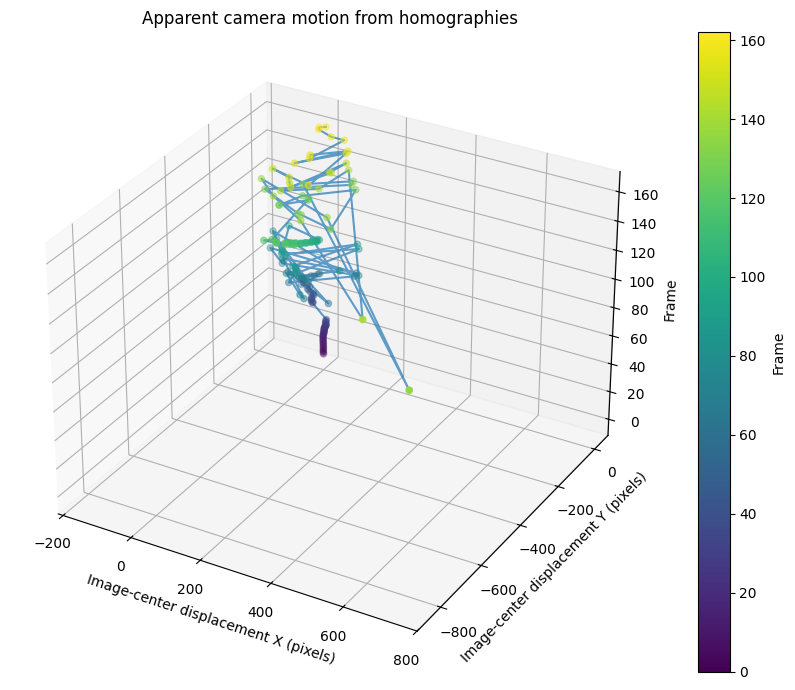

In [5]:
import matplotlib.pyplot as plt

# Image center and its reference-frame position
center = np.array([[[W / 2, H / 2]]], dtype=np.float32)
reference_center = center.reshape(2)

motion = []
frame_numbers = []

for frame_idx, Hmat in enumerate(homographies):
    if Hmat is None or not np.isfinite(Hmat).all():
        continue

    mapped_center = cv2.perspectiveTransform(center, Hmat).reshape(2)
    displacement = mapped_center - reference_center

    if np.isfinite(displacement).all():
        motion.append(displacement)
        frame_numbers.append(frame_idx)

motion = np.asarray(motion)
frame_numbers = np.asarray(frame_numbers)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

sc = ax.scatter(
    motion[:, 0],
    motion[:, 1],
    frame_numbers,
    c=frame_numbers,
    cmap="viridis",
    s=20,
)
ax.plot(motion[:, 0], motion[:, 1], frame_numbers, alpha=0.7)

ax.set_xlabel("Image-center displacement X (pixels)")
ax.set_ylabel("Image-center displacement Y (pixels)")
ax.set_zlabel("Frame")
ax.set_title("Apparent camera motion from homographies")
fig.colorbar(sc, ax=ax, label="Frame")
plt.tight_layout()
plt.show()

In [6]:

# ------------------------------------------------------------
# 6. Track the object
# ------------------------------------------------------------
#
# For now, manually specify the object's image position
# in frame 0.
#
# Example:
# object_point = [640, 360]
# ------------------------------------------------------------

object_point = np.array([
    [640.0, 360.0]
], dtype=np.float32)


# ------------------------------------------------------------
# 7. Example: object observed in frame t
# ------------------------------------------------------------

t = len(frames) // 2

# Replace this with the object's observed pixel position
# in frame t.
object_in_frame_t = np.array([
    [500.0, 400.0]
], dtype=np.float32)


H_t_to_0 = homographies[t]

object_in_reference = cv2.perspectiveTransform(
    object_in_frame_t.reshape(-1, 1, 2),
    H_t_to_0
)

print(
    "Object position in reference frame:",
    object_in_reference.reshape(-1, 2)
)

Object position in reference frame: [[401.03983 303.4185 ]]


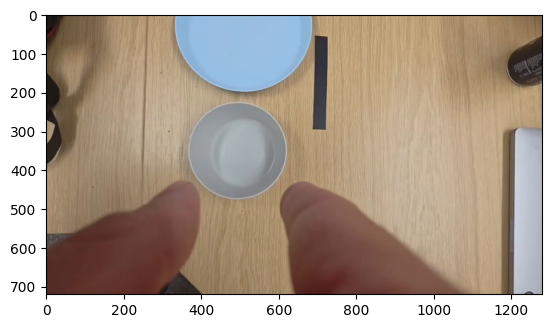

In [7]:
plt.imshow(frames[0])

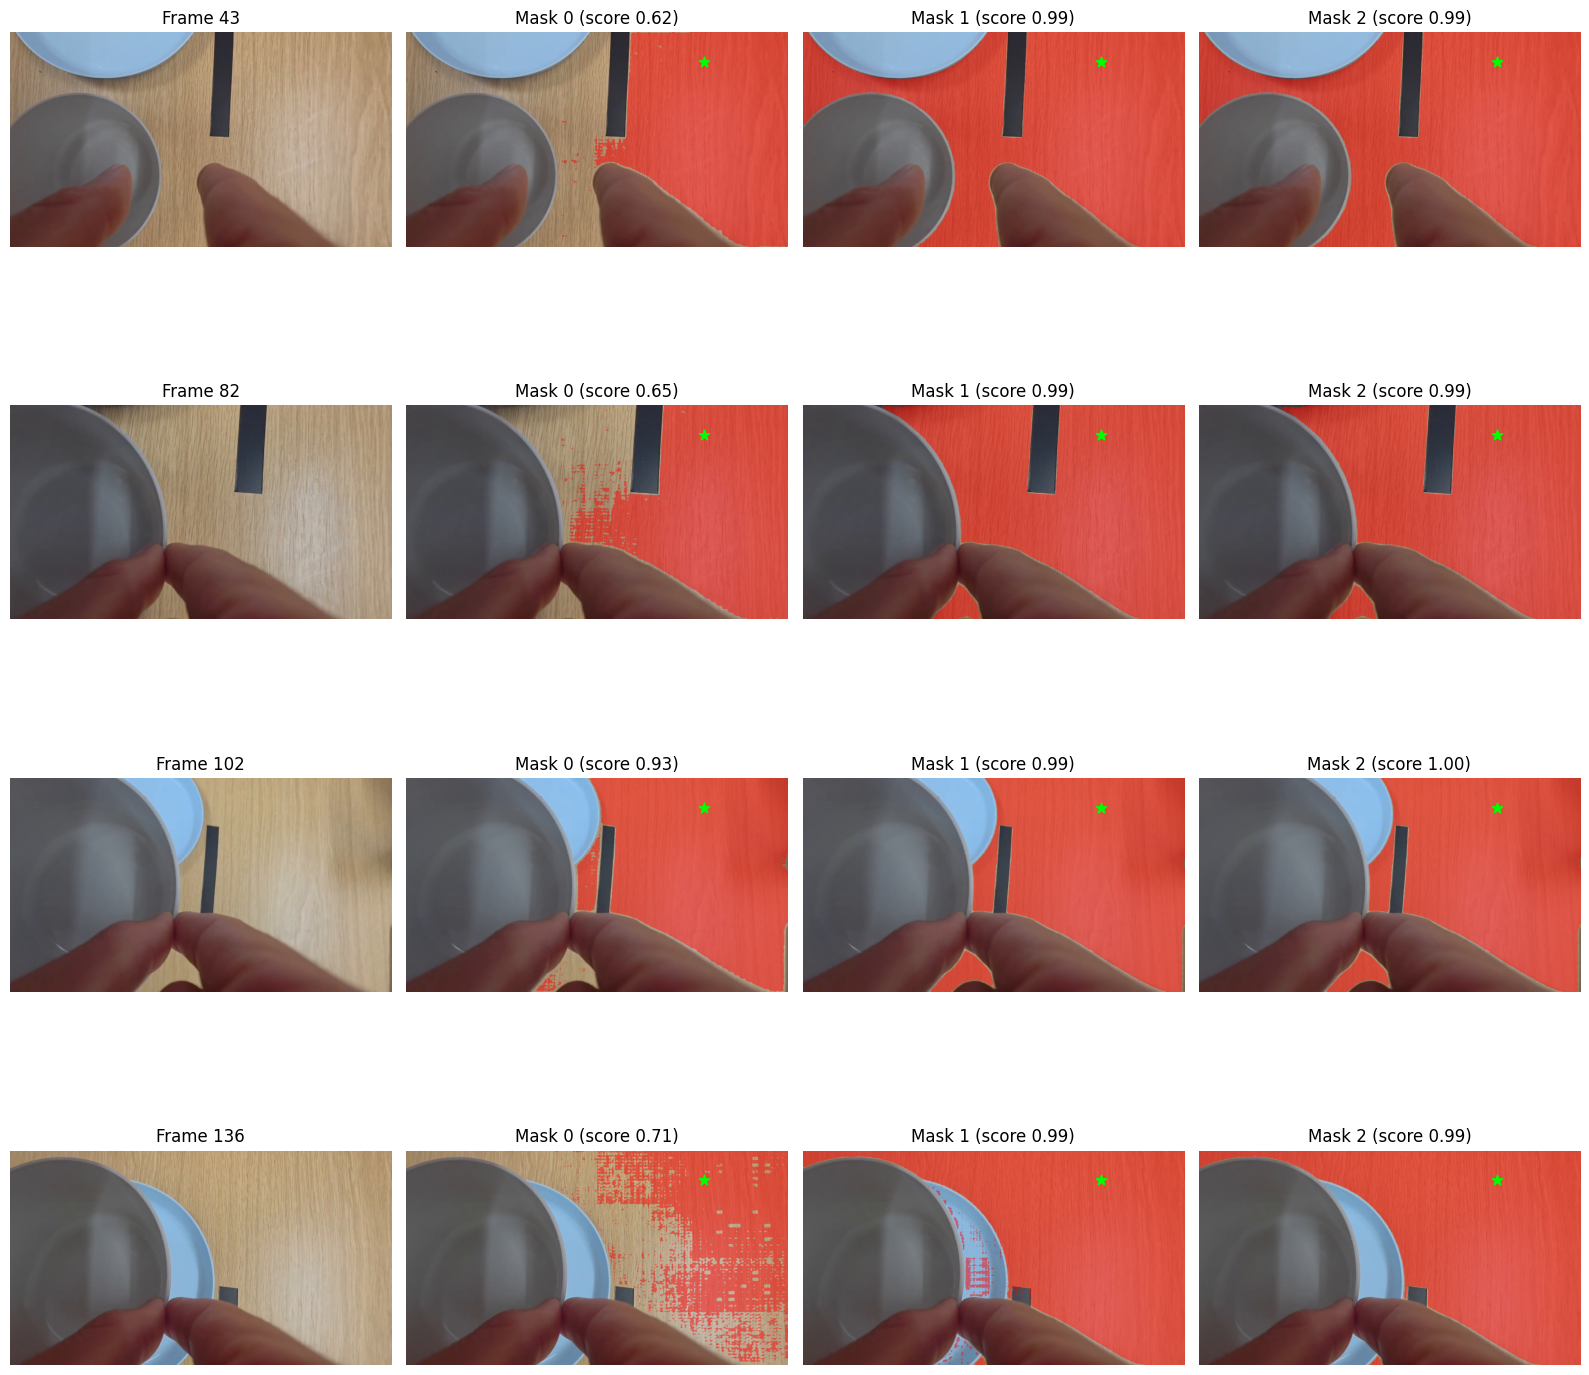

In [8]:
from sam2.sam2_image_predictor import SAM2ImagePredictor

import matplotlib.pyplot as plt

# Load SAM2 image predictor
predictor = SAM2ImagePredictor.from_pretrained("facebook/sam2-hiera-large")

# Randomly sample frames
rng = np.random.default_rng(0)
num_samples = 4
sample_indices = np.sort(rng.choice(len(frames), size=num_samples, replace=False))

# Prompt: the object point (frame 0 coordinates), used as a foreground click
object_point = np.array([
    [1000.0, 100.0],
], dtype=np.float32)
prompt_point = object_point.copy()  # [[x, y]]
prompt_label = np.array([1])

num_masks = 3  # SAM2 returns 3 masks when multimask_output=True

fig, axes = plt.subplots(
    num_samples,
    1 + num_masks,
    figsize=(4 * (1 + num_masks), 4 * num_samples),
)

if num_samples == 1:
    axes = axes[None, :]  # keep 2D indexing

for row, idx in enumerate(sample_indices):
    frame = frames[idx]

    with torch.inference_mode():
        predictor.set_image(frame)
        masks, scores, _ = predictor.predict(
            point_coords=prompt_point,
            point_labels=prompt_label,
            multimask_output=True,
        )

    axes[row, 0].imshow(frame)
    axes[row, 0].set_title(f"Frame {idx}")
    axes[row, 0].axis("off")

    color = np.array([255, 0, 0], dtype=np.uint8)

    for j, (mask, score) in enumerate(zip(masks, scores), start=1):
        mask = mask.astype(bool)

        overlay = frame.copy()
        overlay[mask] = (0.5 * overlay[mask] + 0.5 * color).astype(np.uint8)

        axes[row, j].imshow(overlay)
        axes[row, j].scatter(*prompt_point[0], c="lime", s=60, marker="*")
        axes[row, j].set_title(f"Mask {j - 1} (score {score:.2f})")
        axes[row, j].axis("off")

plt.tight_layout()
plt.show()

In [9]:
import os
import torch
import numpy as np
from sam2.build_sam import build_sam2_video_predictor

output_path = "best_detections.mp4"
height, width = frames[0].shape[:2]

writer = cv2.VideoWriter(
    output_path,
    cv2.VideoWriter_fourcc(*"mp4v"),
    30,  # output FPS
    (width, height),
)

object_point = np.array([
    [100.0, 1000.0],
], dtype=np.float32)
prompt_point = object_point.copy()  # [[x, y]]
prompt_label = np.array([1])

# Load model configuration and checkpoint
model_cfg = "configs/sam2.1/sam2.1_hiera_l.yaml"
sam2_checkpoint = "./sam2_checkpoints/sam2.1_hiera_large.pt"
video_dir = "human_demo_3.mp4"

# 2. Initialize the video predictor
predictor = build_sam2_video_predictor(model_cfg, sam2_checkpoint)
inference_state = predictor.init_state(video_path=video_dir)

# assign this tracking sequence an arbitrary unique object_id (e.g., 1)
_, out_obj_ids, out_mask_logits = predictor.add_new_points_or_boxes(
    inference_state=inference_state,
    frame_idx=0,
    obj_id=1,
    points=points,
    labels=labels,
)

try:
    for frame_idx, frame in enumerate(frames):

        with torch.inference_mode():
            predictor.set_image(frame)
            masks, scores, _ = predictor.predict(
                point_coords=prompt_point,
                point_labels=prompt_label,
                multimask_output=True,
            )

        best_idx = int(np.argmax(scores))
        best_mask = masks[best_idx].astype(bool)
        best_score = float(scores[best_idx])

        output_frame = frame.copy()
        output_frame[best_mask] = (
            0.5 * output_frame[best_mask] + 0.5 * np.array([255, 0, 0])
        ).astype(np.uint8)

        cv2.putText(
            output_frame,
            f"Frame {frame_idx} | score {best_score:.2f}",
            (20, 35),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 255, 0),
            2,
        )

        if best_score > 0.9:
            moments = cv2.moments(best_mask.astype(np.uint8))
            if moments["m00"] > 0:
                mask_center = (
                    int(moments["m10"] / moments["m00"]),
                    int(moments["m01"] / moments["m00"]),
                )
                cv2.circle(output_frame, mask_center, 8, (0, 255, 255), -1)
                prompt_point[0] = np.array(mask_center, dtype=np.float32)

        writer.write(cv2.cvtColor(output_frame, cv2.COLOR_RGB2BGR))
finally:
    writer.release()

print(f"Saved video to {output_path}")


FileNotFoundError: [Errno 2] No such file or directory: './sam2_checkpoints/sam2.1_hiera_large.pt'

In [ ]:
def show_mask(mask, ax, obj_id=None, random_color=False):
    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        cmap = plt.get_cmap("tab10")
        cmap_idx = 0 if obj_id is None else obj_id
        color = np.array([*cmap(cmap_idx)[:3], 0.6])
    h, w = mask.shape[-2:]
    mask_image = mask.reshape(h, w, 1) * color.reshape(1, 1, -1)
    ax.imshow(mask_image)


def show_points(coords, labels, ax, marker_size=200):
    pos_points = coords[labels==1]
    neg_points = coords[labels==0]
    ax.scatter(pos_points[:, 0], pos_points[:, 1], color='green', marker='*', s=marker_size, edgecolor='white', linewidth=1.25)
    ax.scatter(neg_points[:, 0], neg_points[:, 1], color='red', marker='*', s=marker_size, edgecolor='white', linewidth=1.25)


def show_box(box, ax):
    x0, y0 = box[0], box[1]
    w, h = box[2] - box[0], box[3] - box[1]
    ax.add_patch(plt.Rectangle((x0, y0), w, h, edgecolor='green', facecolor=(0, 0, 0, 0), lw=2))

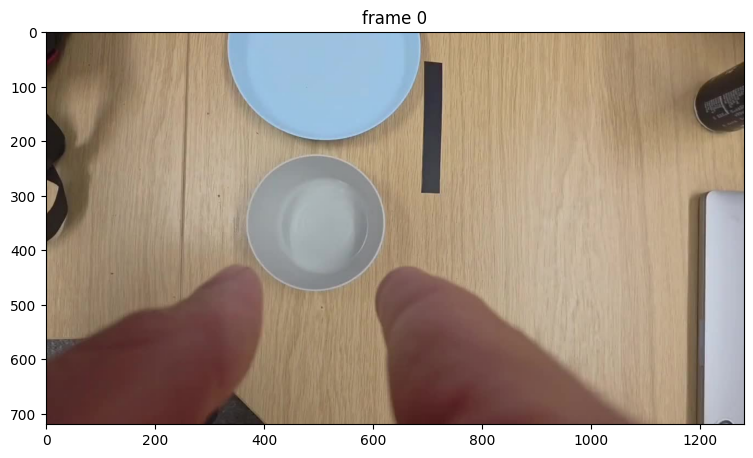

In [ ]:
# `video_dir` a directory of JPEG frames with filenames like `<frame_index>.jpg`
video_dir = "./human_demo_4_frames"

# scan all the JPEG frame names in this directory
frame_names = [
    p for p in os.listdir(video_dir)
    if os.path.splitext(p)[-1] in [".jpg", ".jpeg", ".JPG", ".JPEG"]
]
frame_names.sort(key=lambda p: int(os.path.splitext(p)[0].split('_')[-1]))

# take a look the first video frame
frame_idx = 0
plt.figure(figsize=(9, 6))
plt.title(f"frame {frame_idx}")
plt.imshow(Image.open(os.path.join(video_dir, frame_names[frame_idx])))

In [ ]:
inference_state = predictor.init_state(video_path=video_dir)

frame loading (JPEG): 100%|██████████| 163/163 [00:01<00:00, 84.14it/s]


/home/liyouzhou/LearningFromHumanVideo/.venv/lib/python3.10/site-packages/sam2/sam2_video_predictor.py:786: UserWarning: cannot import name '_C' from 'sam2' (/home/liyouzhou/LearningFromHumanVideo/.venv/lib/python3.10/site-packages/sam2/__init__.py)

Skipping the post-processing step due to the error above. You can still use SAM 2 and it's OK to ignore the error above, although some post-processing functionality may be limited (which doesn't affect the results in most cases; see https://github.com/facebookresearch/sam2/blob/main/INSTALL.md).
  pred_masks_gpu = fill_holes_in_mask_scores(


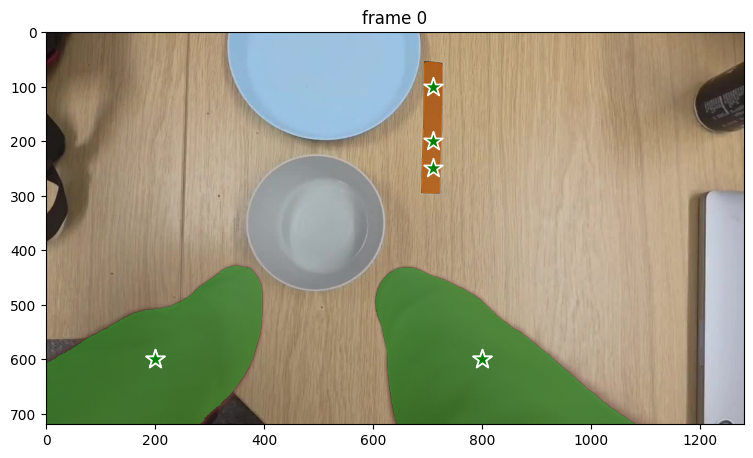

In [ ]:
predictor.reset_state(inference_state)
prompts = {}
ann_frame_idx = 0  # the frame index we interact with

ann_obj_id = 1  # give a unique id to each object we interact with (it can be any integers)
points = np.array([[710, 100], [710, 200], [710, 250]], dtype=np.float32)
labels = np.array([1, 1, 1], np.int32)
prompts[ann_obj_id] = points, labels
ann_obj_id = 2
points = np.array([[200, 600], [800, 600]], dtype=np.float32)
labels = np.array([1, 1], np.int32)
prompts[ann_obj_id] = points, labels

for ann_obj_id, (points, labels) in prompts.items():
    _, out_obj_ids, out_mask_logits = predictor.add_new_points_or_box(
        inference_state=inference_state,
        frame_idx=ann_frame_idx,
        obj_id=ann_obj_id,
        points=points,
        labels=labels,
    )

# show the results on the current (interacted) frame
plt.figure(figsize=(9, 6))
plt.title(f"frame {ann_frame_idx}")
plt.imshow(Image.open(os.path.join(video_dir, frame_names[ann_frame_idx])))
show_points(points, labels, plt.gca())
for i, out_obj_id in enumerate(out_obj_ids):
    show_points(*prompts[out_obj_id], plt.gca())
    show_mask((out_mask_logits[i] > 0.0).cpu().numpy(), plt.gca(), obj_id=out_obj_id)

propagate in video: 100%|██████████| 163/163 [00:18<00:00,  8.59it/s]


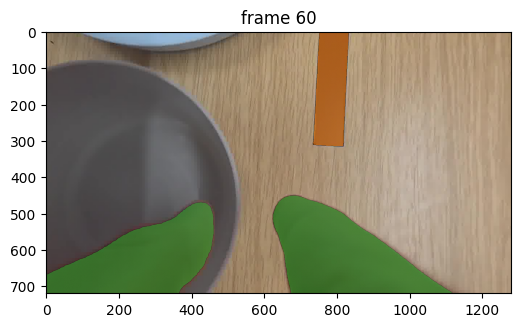

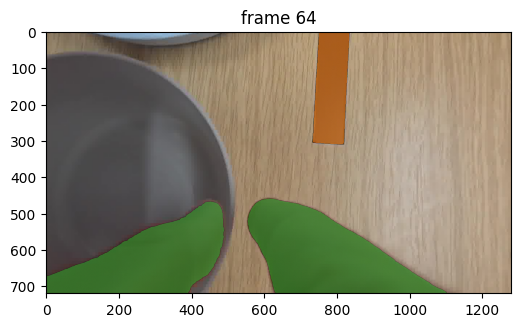

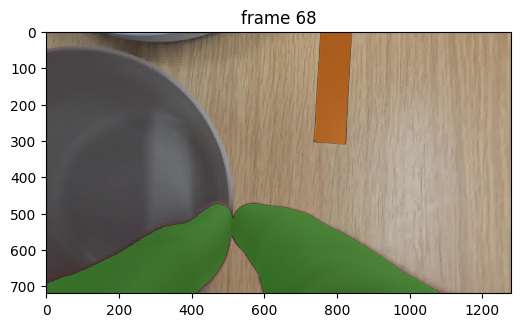

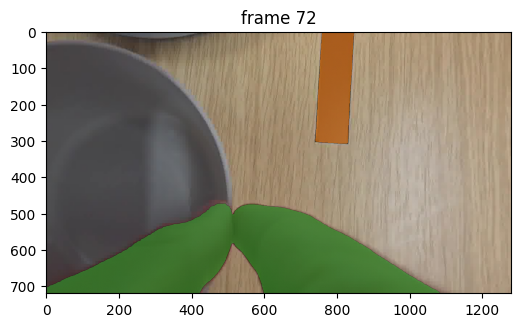

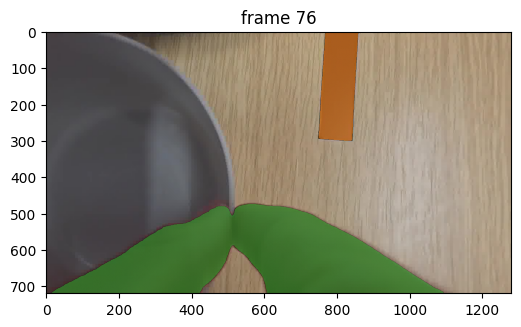

In [ ]:
# run propagation throughout the video and collect the results in a dict
video_segments = {}  # video_segments contains the per-frame segmentation results
for out_frame_idx, out_obj_ids, out_mask_logits in predictor.propagate_in_video(inference_state):
    video_segments[out_frame_idx] = {
        out_obj_id: (out_mask_logits[i] > 0.0).cpu().numpy()
        for i, out_obj_id in enumerate(out_obj_ids)
    }

# render the segmentation results every few frames
vis_frame_stride = 30
plt.close("all")
# for out_frame_idx in range(0, len(frame_names), vis_frame_stride):
for out_frame_idx in range(60, 80, 4):
    plt.figure(figsize=(6, 4))
    plt.title(f"frame {out_frame_idx}")
    plt.imshow(Image.open(os.path.join(video_dir, frame_names[out_frame_idx])))
    for out_obj_id, out_mask in video_segments[out_frame_idx].items():
        show_mask(out_mask, plt.gca(), obj_id=out_obj_id)

Processing frame segment: 0
Frame 0: width = 40 px, height = 243 px
Processing frame segment: 1
Frame 1: width = 40 px, height = 243 px
Processing frame segment: 2
Frame 2: width = 40 px, height = 243 px
Processing frame segment: 3
Frame 3: width = 40 px, height = 243 px
Processing frame segment: 4
Frame 4: width = 40 px, height = 243 px
Processing frame segment: 5
Frame 5: width = 40 px, height = 244 px
Processing frame segment: 6
Frame 6: width = 40 px, height = 244 px
Processing frame segment: 7
Frame 7: width = 41 px, height = 244 px
Processing frame segment: 8
Frame 8: width = 41 px, height = 244 px
Processing frame segment: 9
Frame 9: width = 41 px, height = 244 px
Processing frame segment: 10
Frame 10: width = 41 px, height = 244 px
Processing frame segment: 11
Frame 11: width = 41 px, height = 244 px
Processing frame segment: 12
Frame 12: width = 41 px, height = 245 px
Processing frame segment: 13
Frame 13: width = 41 px, height = 246 px
Processing frame segment: 14
Frame 14: w

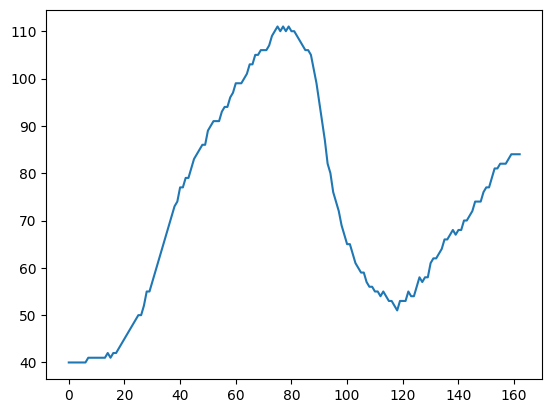

In [ ]:
widths = []
for frame_segment in video_segments:
    print(f"Processing frame segment: {frame_segment}")
    for out_obj_id, out_mask in video_segments[frame_segment].items():
        if out_obj_id != 1:  # only process object with ID 1
            continue
        mask = np.asarray(out_mask).squeeze()
        if mask.dtype != bool:
            mask = mask > 0.0

        ys, xs = np.nonzero(mask)
        if len(xs) == 0:
            print(f"Frame {frame_segment}: empty mask, skipping")
            continue

        x, y = xs.min(), ys.min()
        w = int(xs.max() - x + 1)
        h = int(ys.max() - y + 1)
        print(f"Frame {frame_segment}: width = {w} px, height = {h} px")
        widths.append(w)

plt.plot(widths)

Processing frame segment: 0
3
Frame 0: distance = 567.23 px (areas 78184, 76247)
Processing frame segment: 1
3
Frame 1: distance = 567.04 px (areas 77889, 76225)
Processing frame segment: 2
3
Frame 2: distance = 567.03 px (areas 77961, 76235)
Processing frame segment: 3
3
Frame 3: distance = 567.27 px (areas 78089, 76467)
Processing frame segment: 4
3
Frame 4: distance = 567.79 px (areas 78313, 76707)
Processing frame segment: 5
3
Frame 5: distance = 568.13 px (areas 78309, 76913)
Processing frame segment: 6
3
Frame 6: distance = 568.59 px (areas 78298, 77058)
Processing frame segment: 7
3
Frame 7: distance = 569.47 px (areas 78521, 77325)
Processing frame segment: 8
3
Frame 8: distance = 569.02 px (areas 78428, 77496)
Processing frame segment: 9
3
Frame 9: distance = 569.26 px (areas 78503, 77760)
Processing frame segment: 10
3
Frame 10: distance = 570.09 px (areas 78759, 77958)
Processing frame segment: 11
3
Frame 11: distance = 570.07 px (areas 78755, 78059)
Processing frame segment

Text(0, 0.5, 'Island centroid distance (px)')

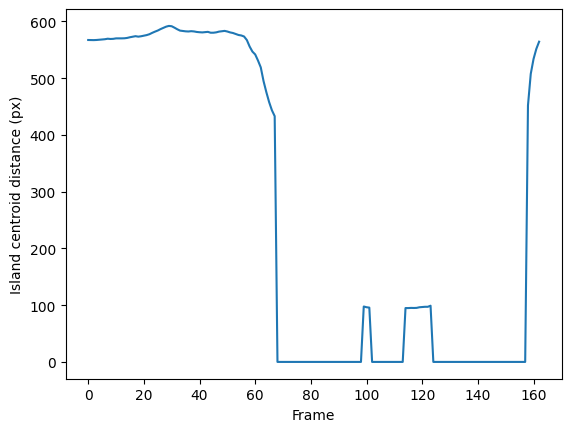

In [ ]:
gripper_open = []
for frame_idx in sorted(video_segments):
    print(f"Processing frame segment: {frame_idx}")
    for out_obj_id, out_mask in video_segments[frame_idx].items():
        if out_obj_id != 2:  # only process object with ID 2
            continue

        mask = np.asarray(out_mask).squeeze()
        if mask.dtype != bool:
            mask = mask > 0.0

        mask_u8 = (mask.astype(np.uint8)) * 255
        num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
            mask_u8, connectivity=8
        )

        # label 0 is background, so we need at least 2 foreground islands
        if num_labels == 1:
            dist = 0.0
        elif num_labels >= 3:  # exactly two foreground islands
            # Pick the two largest components by area, ignoring background
            print(num_labels)
            comps = sorted(
                (
                    (stats[i, cv2.CC_STAT_AREA], centroids[i])
                    for i in range(1, num_labels)
                ),
                key=lambda t: t[0],
                reverse=True,
            )

            (area1, c1), (area2, c2) = comps[0], comps[1]
            dist = float(np.linalg.norm(c1 - c2))
        else:
            dist = 0.0
            area1, area2 = 0, 0

        print(
            f"Frame {frame_idx}: distance = {dist:.2f} px "
            f"(areas {int(area1)}, {int(area2)})"
        )
        gripper_open.append(dist)

plt.plot(gripper_open)
plt.xlabel("Frame")
plt.ylabel("Island centroid distance (px)")

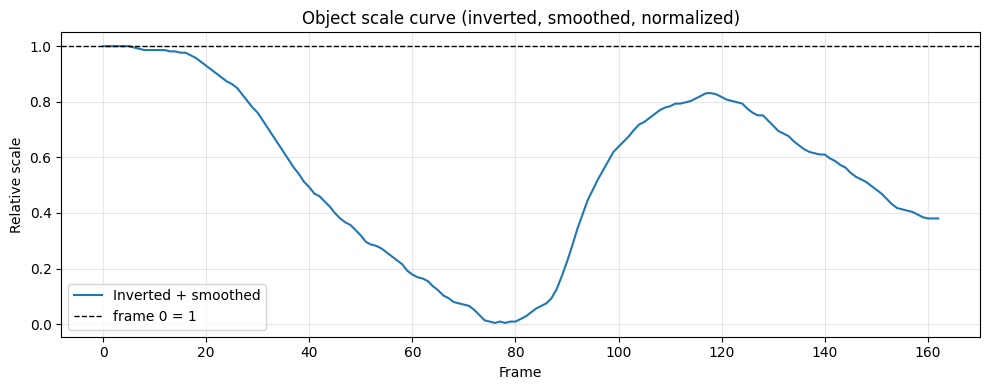

In [ ]:
# Invert, smooth, and normalize the width curve so frame 0 = 1
w = np.asarray(widths, dtype=np.float32)
if w.size == 0:
    raise ValueError("widths is empty")

# Invert: larger width -> smaller value (approximate inverse distance/scale)
curve = - w

min_curve = np.min(curve)
max_curve = np.max(curve)
curve = (curve - min_curve) / (max_curve - min_curve)

# Smooth with a centered moving average
window = min(3, max(3, len(curve) // 10))
if window % 2 == 0:
    window += 1

kernel = np.ones(window, dtype=np.float32) / window
pad = window // 2
padded_curve = np.pad(curve, (pad, pad), mode="edge")
smoothed = np.convolve(padded_curve, kernel, mode="valid")

# Normalize so the first frame is exactly 1
# smoothed = smoothed / smoothed[0]

# Keep a clean variable name for later use
relative_scale = smoothed

plt.figure(figsize=(10, 4))
plt.plot(np.arange(len(relative_scale)), relative_scale, label="Inverted + smoothed")
plt.axhline(1.0, color="k", linestyle="--", lw=1, label="frame 0 = 1")
plt.xlabel("Frame")
plt.ylabel("Relative scale")
plt.title("Object scale curve (inverted, smoothed, normalized)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
gripper_open

[567.227505272296,
 567.0392119889641,
 567.025819011692,
 567.2697031235109,
 567.793899298684,
 568.1311546684028,
 568.5862264419649,
 569.4725520535827,
 569.0200749980614,
 569.2605424576614,
 570.0874461721386,
 570.0690799576255,
 570.0986023470533,
 570.235427164443,
 570.8805579740061,
 572.0789943669096,
 573.0656984598431,
 573.9527105094897,
 573.1033167980229,
 573.8115310580167,
 574.9334632794158,
 575.8643043158014,
 577.4105125977419,
 579.821438045441,
 581.975399515773,
 583.9110272634646,
 586.4260984617392,
 588.5064253415707,
 590.7381198413658,
 592.025954029238,
 591.4680657012835,
 588.9370791993384,
 586.1325264867507,
 583.7489496929563,
 583.0625682204791,
 582.4892306999203,
 582.2202638314756,
 582.7531302761458,
 582.3259788332301,
 581.3999223387594,
 580.9000564489241,
 580.5994917586473,
 581.1121602662868,
 581.5654924669616,
 580.0396373428459,
 580.0667508440457,
 580.7015094388604,
 581.9928892088934,
 582.6548834584953,
 583.2677445704613,
 582.16

In [ ]:
import csv


with open(csv_path, "w", newline="") as csv_file:
    writer = csv.DictWriter(
        csv_file,
        fieldnames=["frame", "gripper_width_px", "object_scale"],
    )
    writer.writeheader()
    for frame_idx in range(len(gripper_open)):
        writer.writerow({
            "frame": frame_idx + 1,
            "gripper_width_px": gripper_open[frame_idx],
            "object_scale": relative_scale[frame_idx],
        })

print(f"Saved CSV to {csv_path}")

Saved CSV to ./human_demo_4_frames/gripper_and_object_scale.csv


In [ ]:
!rm best_detections_h264.mp4
!ffmpeg -hide_banner -loglevel error -n -i best_detections.mp4 -c:v libx264 -pix_fmt yuv420p -movflags +faststart -an best_detections_h264.mp4

[out#0/mp4 @ 0x61b81c6dc600] Output file does not contain any stream
Error opening output file best_detections_h264.mp4.
Error opening output files: Invalid argument


In [ ]:
display(Video("best_detections_h264.mp4", embed=True, html_attributes="controls autoplay loop"))

In [ ]:
import numpy as np
data =np.load("human_demo_4_embeddings.npy")
data["gripper_state"]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 0, 0, 0, 0, 0], dtype=uint8)